# Heuers' statistical Football model

The following implementation aims to recreate the Football model of Prof. Dr. Andreas Heuer.

In [129]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from functools import lru_cache
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
AVG_HF_ADV = 0.3672508214676889  # from DB
AVG_GA = 2.7175246440306681 # from DB
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [130]:
# Helperfunctions
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)
    
    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


## Step 1 - Homefield advantage

In [131]:
df_country_season_homefield_adv = pd.read_csv("data/hf_adv.csv", sep=";")

df_country_season_homefield_adv

,country,season,matchnumber,ht_name,at_name,curr_hf_adv,past_hf_adv,actual_hf_adv
0,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.0,1
1,ENG,14,1,Burnley,Chelsea,0.000000,0.0,-2
2,ENG,14,1,Leicester,Everton,0.000000,0.0,0
3,ENG,14,1,Liverpool,Southampton,0.000000,0.0,1
4,ENG,14,1,Man Utd,Swansea,0.000000,0.0,-1
...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Fiorentina,CFC Genoa,0.275676,0.0,0
9126,ITA,18,38,Frosinone,Chievo,0.275676,0.0,0
9127,ITA,18,38,Inter,Empoli,0.275676,0.0,1
9128,ITA,18,38,Sampdoria,Juventus,0.275676,0.0,2


In [132]:
def h_country_season_homefield_adv(country, season, matchnumber):
    if matchnumber == 1:
        return AVG_HF_ADV
        
    sub_df = df_country_season_homefield_adv.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_hf_adv",
                "curr_hf_adv"]].values
    y = sub_df["actual_hf_adv"].values

    model = LinearRegression(positive=True).fit(X, y)
    
    input_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["past_hf_adv",
                      "curr_hf_adv"]].values

    return model.predict(input)[0]


print("Homefield advantage:", h_country_season_homefield_adv("ENG", 17, 8))


Homefield advantage: 0.3469387755102041


## Step 2 - Goalamount per match

In [133]:
df_country_season_goalamount = pd.read_csv(
    "data/ga.csv", sep=";")

df_country_season_goalamount

,country,season,matchnumber,ht_name,at_name,curr_ga,past_ga,actual_ga
0,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,3
1,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,4
2,ENG,14,1,Leicester,Everton,0.000000,0.000000,4
3,ENG,14,1,Liverpool,Southampton,0.000000,0.000000,3
4,ENG,14,1,Man Utd,Swansea,0.000000,0.000000,3
...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Fiorentina,CFC Genoa,2.675676,2.735965,0
9126,ITA,18,38,Frosinone,Chievo,2.675676,2.735965,0
9127,ITA,18,38,Inter,Empoli,2.675676,2.735965,3
9128,ITA,18,38,Sampdoria,Juventus,2.675676,2.735965,2


In [134]:
def h_country_season_goalamount(country, season, matchnumber):
    if matchnumber == 1:
        return AVG_GA
        
    sub_df = df_country_season_goalamount.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_ga",
                "curr_ga"]].values 
    y = sub_df["actual_ga"].values

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["past_ga",
                      "curr_ga"]].values

    return model.predict(input)[0]


print("Goalamount:", h_country_season_goalamount("GER", 18, 8))


Goalamount: 2.758234611337038


## Step 3: Teamstrength and expected goaldifference + Step 4: Specialty for promoters

In [135]:
df_matches = pd.read_csv('data/matches_heuer.csv', sep=';')

ga_label = "actual_goalamount"
gd_label = "actual_goaldiff"

df_matches

,country,season,matchnumber,teamname,curr_eff_chancediff,past_chancediff_combined,curr_eff_chanceamount,past_chanceamount,curr_fitness,market_value_ln_relative,is_promoter,is_home,actual_goalamount,actual_goaldiff
0,ENG,14,1,Queens Park Rangers,0.000000,0.000000,0.000000,0.000000,0.000000,-0.392415,True,True,1,-1
1,ENG,14,1,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,-0.348740,False,False,1,1
2,ENG,14,1,Newcastle,0.000000,0.000000,0.000000,0.000000,0.000000,-0.169272,False,True,2,-2
3,ENG,14,1,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,1.002768,False,False,2,2
4,ENG,14,1,Burnley,0.000000,0.000000,0.000000,0.000000,0.000000,-1.140622,True,True,4,-2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18255,ITA,18,38,Napoli,5.242267,5.293421,3.415385,8.877193,3.375719,1.070083,False,False,5,-1
18256,ITA,18,38,Inter,2.881676,2.380263,1.042860,6.754386,1.768259,1.024225,False,True,3,1
18257,ITA,18,38,Empoli,-3.462648,-3.058772,-0.805584,4.403509,2.088522,-0.738824,True,False,3,-1
18258,ITA,18,38,Cagliari,-3.170633,-1.972368,-1.823289,4.824561,-3.719535,-0.358838,False,True,3,-1


In [136]:
def h_teamstrength(country, season, matchnumber, teamname):
    if matchnumber == 1:
        return 0

    sub_df = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chancediff_combined",
                "curr_eff_chancediff", "curr_fitness", "market_value_ln_relative"]].values
    y = []

    # one team is only responsible for half of the goaldiff
    for index, row in sub_df.iterrows():
        goal_diff = row["actual_goaldiff"]
        if row["is_home"]:
            goal_diff -= AVG_HF_ADV
        else:
            goal_diff += AVG_HF_ADV
        y.append(goal_diff/2)

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_matches.query(
        f"season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")

    # Homefield advantage correction
    homefield_matches = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber} and teamname == '{teamname}' and is_home").count()["is_home"]

    if matchnumber > 1:
        additional_homefield_matches = homefield_matches - \
            ((matchnumber - 1) - homefield_matches)
        if additional_homefield_matches > 0:
            input_df["curr_eff_chancediff"] -= (additional_homefield_matches * \
                h_country_season_homefield_adv(country, season, matchnumber) * 4) / (matchnumber - 1)

    # Step 4: Specialty for promoters
    if input_df.iloc[0]["is_promoter"]:
        input_df["past_chancediff_combined"] = input_df["past_chancediff_combined"] * \
            0.45 * model.coef_[1]
        input_df["curr_eff_chancediff"] = input_df["curr_eff_chancediff"] * 0.45 * model.coef_[1]

    input = input_df[["past_chancediff_combined",
                      "curr_eff_chancediff", "curr_fitness","market_value_ln_relative"]].values

    teamstrength = model.predict(input)[0]

    if input_df.iloc[0]["is_promoter"]:
        teamstrength -= (13/34)

    return teamstrength


print("Teamstrength:", h_teamstrength("ENG", 16, 12, "Leicester"))

Teamstrength: -0.07398843117062383


## Step 5: Expected goalamount per match

In [137]:
def h_goalamount_from_avg_per_match(country, season, matchnumber, teamname):
    if matchnumber == 1:
        return 0

    sub_df = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chanceamount", "curr_eff_chanceamount"]].values 
    y = []
    for index, row in sub_df.iterrows():
        y.append(row["actual_goalamount"] - AVG_GA)

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_matches.query(
        f"season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chanceamount", "curr_eff_chanceamount"]].values

    return model.predict(input)[0]

print("Goalamount from avg:", h_goalamount_from_avg_per_match("GER", 16, 19, "Bayern"))


Goalamount from avg: 0.5728719051280874


## Step 6: Predicted Goals

In [138]:
def predicted_goals(country, season, matchnumber, hometeam, awayteam):
    goalamount = h_goalamount_from_avg_per_match(
        country, season, matchnumber, hometeam) + h_goalamount_from_avg_per_match(country, season, matchnumber, awayteam) + h_country_season_goalamount(country, season, matchnumber)
    goaldiff = h_country_season_homefield_adv(country, season, matchnumber) + h_teamstrength(country, season, matchnumber, hometeam) - h_teamstrength(country, season, matchnumber, awayteam)
    return (goalamount, goaldiff)


## Step 7: Dependence on matchnumber

In [139]:
def matchnumber_goalamount_multiplier(country, matchnumber):
    # Uncertain
    if country == 'GER':
        if matchnumber < 18:
            return 1.02
        elif matchnumber < 31:
            return 0.95
        else:
            return 1.2
    else:
        if matchnumber < 19:
            return 1.02
        elif matchnumber < 35:
            return 0.95
        else:
            return 1.2


## Final: Full run on dataset to measure goalamount and goaldifference error

In [140]:
def predict(country, season, matchnumber, hometeam, awayteam):
    amount, diff = predicted_goals(country, season, matchnumber, hometeam, awayteam)

    home_score, away_score = score_from_amount_and_diff(amount, diff)

    home_score *= matchnumber_goalamount_multiplier(country, matchnumber)
    away_score *= matchnumber_goalamount_multiplier(country, matchnumber)

    return (home_score+ away_score), (home_score - away_score)


## Error per season

In [142]:
do_entire_run = True

if do_entire_run:
    error_dict = dict()
    ga_generalization_error, gd_generalization_error = 0,0
    ga_error, gd_error = [], []

    for index, row in df_matches.iterrows():
        if index % 2 == 0:
            hometeam = row["teamname"]
            continue
        else:
            print("Predicting:", row["country"],
                  row["season"], row["matchnumber"], hometeam, row["teamname"])
            awayteam = row["teamname"]
            ga_pred, gd_pred = predict(
                row["country"], row["season"], row["matchnumber"], hometeam, awayteam)

            curr_ga_error = np.abs(ga_pred - row["actual_goalamount"])
            curr_gd_error = np.abs(gd_pred + row["actual_goaldiff"])

            # error list for distribution
            ga_error.append(round(ga_pred - row[ga_label]))
            gd_error.append(round(gd_pred + row[gd_label]))

            # generalization error
            if row["season"] in [17,18]:
                ga_generalization_error += curr_ga_error
                gd_generalization_error += curr_gd_error 

            # for training error plot
            if not row["season"] in error_dict.keys():
                error_dict[row["season"]] = {}
            if not row["country"] in error_dict[row["season"]].keys():
                error_dict[row["season"]][row["country"]] = {"ga":0,"gd":0}

            if row["country"] == "GER":
                error_dict[row["season"]][row["country"]
                                        ]["ga"] += (curr_ga_error / 306)
                error_dict[row["season"]][row["country"]
                                        ]["gd"] += (curr_gd_error / 306)
            else:
                error_dict[row["season"]][row["country"]
                                          ]["ga"] += (curr_ga_error / 380)
                error_dict[row["season"]][row["country"]
                                          ]["gd"] += (curr_gd_error / 380)

    print("GA generalization error:", ga_generalization_error / (NUM_OF_MATCHES_IN_A_SEASON * 2))
    print("GD generalization error:", gd_generalization_error /
            (NUM_OF_MATCHES_IN_A_SEASON * 2))


# GA generalization error: 1.3253356077389067
# GD generalization error: 1.2773493526221034


Predicting: ENG 14 1 Queens Park Rangers Hull
Predicting: ENG 14 1 Newcastle Man City
Predicting: ENG 14 1 Burnley Chelsea
Predicting: ENG 14 1 Arsenal Crystal Palace
Predicting: ENG 14 1 West Ham Tottenham
Predicting: ENG 14 1 Leicester Everton
Predicting: ENG 14 1 Man Utd Swansea
Predicting: ENG 14 1 West Brom Sunderland
Predicting: ENG 14 1 Liverpool Southampton
Predicting: ENG 14 1 Stoke Aston Villa
Predicting: ENG 14 2 Sunderland Man Utd
Predicting: ENG 14 2 Aston Villa Newcastle
Predicting: ENG 14 2 Tottenham Queens Park Rangers
Predicting: ENG 14 2 Swansea Burnley
Predicting: ENG 14 2 Hull Stoke
Predicting: ENG 14 2 Southampton West Brom
Predicting: ENG 14 2 Everton Arsenal
Predicting: ENG 14 2 Crystal Palace West Ham
Predicting: ENG 14 2 Chelsea Leicester
Predicting: ENG 14 2 Man City Liverpool
Predicting: ENG 14 3 West Ham Southampton
Predicting: ENG 14 3 Burnley Man Utd
Predicting: ENG 14 3 Swansea West Brom
Predicting: ENG 14 3 Man City Stoke
Predicting: ENG 14 3 Leicester A

In [153]:
if do_entire_run:
        print("country;season;ga_error;gd_error")
        for a in error_dict.keys():
                for b in error_dict[a].keys():
                                print(str(b)+";"+str(a)+";" +
                                        str(error_dict[a][b]["ga"])+";"+str(error_dict[a][b]["gd"]))


country;season;ga_error;gd_error
ENG;14;1.3016346784838095;1.1993192485679482
ESP;14;1.3412942982282239;1.2825070286549536
FRA;14;1.313859662196905;1.2078943566286224
GER;14;1.4336303903642889;1.2658046129334646
ITA;14;1.3078631977713304;1.1834526366397744
ENG;15;1.3750744589991752;1.2614631074117613
ESP;15;1.3099202896264526;1.3585603619360131
FRA;15;1.3017729117214452;1.2836609774316416
GER;15;1.3489438136285237;1.3870994653726691
ITA;15;1.2894910506530421;1.2081999142772524
ENG;16;1.3494874346204224;1.3516156989779677
ESP;16;1.428267575932549;1.2895340299113522
FRA;16;1.3019892867690421;1.312665369363272
GER;16;1.4298185176610971;1.3584597913087426
ITA;16;1.3255783080806436;1.2771534201002965
ENG;17;1.3168884824065499;1.292010162578608
ESP;17;1.4025540008981823;1.3106107367818363
FRA;17;1.225207035256327;1.2797188771356107
GER;17;1.2916063935547395;1.272340724721417
ITA;17;1.3444610241167987;1.2395452784349166
ENG;18;1.2938078719220178;1.36213755172564
ESP;18;1.3380076391007492;1.15

In [154]:
if do_entire_run:
        distribution_data = dict()
        for x in range(-10, 10):
                distribution_data[x] = {}
                for y in range(-10, 10):
                        distribution_data[x][y] = 0

        for ga, gd in zip(ga_error, gd_error):
                distribution_data[round(ga)][round(gd)] += 1

        print("ga prediction - actual ga;gd prediction - actual gd;count")
        for key in range(-10, 10):
                for x in distribution_data[key].keys():
                        if key < 4 and key > -4 and x < 4 and x > -4:
                                print(str(key)+";"+str(x)+";" +
                                        str(distribution_data[key][x]))


ga prediction - actual ga;gd prediction - actual gd;count
-3;-3;63
-3;-2;51
-3;-1;79
-3;0;83
-3;1;66
-3;2;43
-3;3;27
-2;-3;73
-2;-2;135
-2;-1;152
-2;0;200
-2;1;144
-2;2;110
-2;3;60
-1;-3;142
-1;-2;204
-1;-1;364
-1;0;296
-1;1;261
-1;2;196
-1;3;99
0;-3;83
0;-2;328
0;-1;451
0;0;599
0;1;366
0;2;215
0;3;119
1;-3;12
1;-2;156
1;-1;510
1;0;506
1;1;470
1;2;219
1;3;39
2;-3;0
2;-2;26
2;-1;245
2;0;492
2;1;347
2;2;79
2;3;6
3;-3;0
3;-2;1
3;-1;30
3;0;208
3;1;116
3;2;5
3;3;0


## Plotting

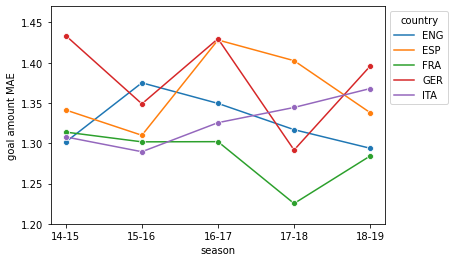

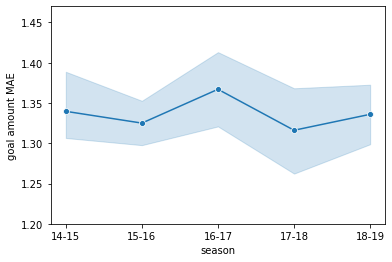

In [155]:
abs_error_df = pd.read_csv("data/abs_error.csv",sep=";")

g = sns.lineplot(x="season", y="ga_error",
           hue="country", data=abs_error_df, marker="o")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xticks([14,15,16,17,18],["14-15","15-16","16-17","17-18","18-19"])
plt.ylabel("goal amount MAE")
plt.ylim(1.20,1.47)
plt.show()

sns.lineplot(x="season", y="ga_error",
            data=abs_error_df, marker="o")
plt.ylabel("goal amount MAE")
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.ylim(1.20, 1.47)
plt.show()


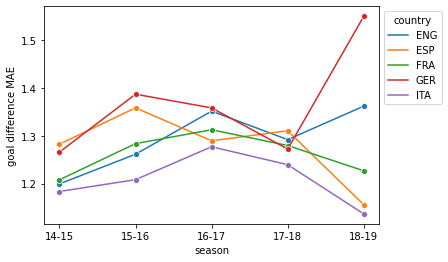

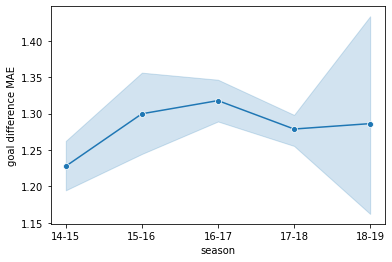

In [157]:
g = sns.lineplot(x="season", y="gd_error",
             hue="country", data=abs_error_df,  marker="o")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.ylabel("goal difference MAE")
#plt.ylim(1.4, 2.1)
plt.show()

sns.lineplot(x="season", y="gd_error",
             data=abs_error_df,  marker="o")
plt.ylabel("goal difference MAE")
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
#plt.ylim(1.4, 2.1)
plt.show()


## prediction distribution

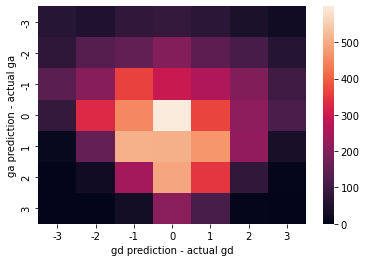

In [158]:
heatmap_df = pd.read_csv("data/distribution.csv",sep=";")

heatmap_df = heatmap_df.pivot(
"ga prediction - actual ga", "gd prediction - actual gd", "count")

sns.heatmap(heatmap_df)
plt.show()
